# stLearn CCI across age and replicates

Runs the stLearn analysis from `09b` on all 4 sections (8 and 13 months, 2 replicates each), one neighbourhood per section, and compares ages. n = 2 sections per age.

Per LR pair and section, `frac_sig` = share of cells with a significant stLearn LR score. Because sections differ in overall signal, each of our pairs is also expressed relative to the database pairs in the same section.

## Imports

In [1]:
import inspect
import os

import numpy as np
import pandas as pd
import scipy.io as sio
import anndata as ad
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from scipy.stats import norm
import stlearn as st

print("stLearn version:", st.__version__)

stLearn version: 1.4.1


## Settings

In [2]:
export_dir = "output/08_STARmapPLUS_CCC_GenePanelCheck/starmap_hpc_export"   # written by 08_STARmapPLUS_CCC_GenePanelCheck.qmd
out_dir    = "output/10b_STARmapPLUS_stlearn_Age_comparison"
os.makedirs(out_dir, exist_ok=True)
morans_shift_path = "output/10_STARmapPLUS_BivariateMoransI_AgeComparison/bivariate_morans_age_shift.csv"   # from 10, optional

CELLTYPE_COL = "celltype_merged"
RADIUS       = 400     # same as 09b
N_PAIRS      = 1000
MIN_SPOTS    = 10
N_PERMS_CCI  = 100
K_MATCHED    = 50      # database pairs with the closest detection used as background per LR pair
N_CPUS       = None
SEED         = 1337
LR_DATABASES = ["connectomeDB2020_lit"]

## Helper functions

In [3]:
def build_section_adata(expr, genes, cells, meta, coords, celltype_col):
    """AnnData for stLearn: log-normalized expression, cell coordinates as imagecol (x) /
    imagerow (y). stLearn only needs these two obs columns when `distance` is given."""
    a = ad.AnnData(X=expr, obs=meta.copy(), var=pd.DataFrame(index=genes))
    a.obs_names = cells
    a.var_names_make_unique()
    # stLearn splits "L_R" strings on "_", so gene names must not contain "_"
    a.var_names = [g.replace("_", "-") for g in a.var_names]
    a.obs["imagecol"] = coords["spatial_1"].to_numpy()
    a.obs["imagerow"] = coords["spatial_2"].to_numpy()
    a.obsm["spatial"] = coords[["spatial_1", "spatial_2"]].to_numpy()
    # plain Python strings (object dtype, not categorical/pandas string): stLearn's numba code needs them
    a.obs[celltype_col] = a.obs[celltype_col].astype(str).replace("nan", "Unknown").astype(object)
    return a


def call_with_supported(fn, **kwargs):
    """Pass only the arguments this stLearn version accepts (e.g. random_state is not in older versions)."""
    accepted = inspect.signature(fn).parameters
    return fn(**{k: v for k, v in kwargs.items() if k in accepted})


def run_stlearn_lr(a, lrs, radius, n_pairs, min_spots, n_cpus, seed, verbose=True):
    """stLearn LR test per cell: LR score from ligand in a cell and receptor in its neighbours
    within `radius` (and the reverse); p-values from random gene pairs with matched expression.
    p-values are then FDR-corrected across the LR pairs tested in each cell (correct_axis='spot')."""
    call_with_supported(st.tl.cci.run, adata=a, lrs=lrs, min_spots=min_spots, distance=radius,
                        n_pairs=n_pairs, n_cpus=n_cpus, random_state=seed, verbose=verbose)
    if "lr_summary" not in a.uns:
        raise RuntimeError("stLearn returned no valid LR pairs -- lower MIN_SPOTS or increase RADIUS.")
    st.tl.cci.adj_pvals(a, correct_axis="spot", pval_adj_cutoff=0.05, adj_method="fdr_bh")
    summ = a.uns["lr_summary"].copy()
    summ.index.name = "lr"
    summ = summ.reset_index()
    summ["ligand"] = summ["lr"].str.split("_").str[0]
    summ["receptor"] = summ["lr"].str.split("_").str[1]
    summ["n_cells"] = a.n_obs
    summ["frac_sig"] = summ["n_spots_sig"] / a.n_obs          # share of cells with a significant LR score
    summ["frac_scored"] = summ["n_spots"] / a.n_obs           # share of cells with any LR score
    return summ


def detection_matched_p(summ, detection, our_lrs, k=50):
    """For each of our pairs: compare its frac_sig with the k database pairs whose ligand and
    receptor detection rates are closest (log10 space). One-sided empirical p (ours higher)."""
    db = summ[~summ["lr"].isin(our_lrs)].copy()
    eps = 1e-4
    def det_xy(df):
        return np.column_stack([np.log10(detection.reindex(df["ligand"]).to_numpy() + eps),
                                np.log10(detection.reindex(df["receptor"]).to_numpy() + eps)])
    tree = cKDTree(det_xy(db))
    rows = []
    for _, r in summ[summ["lr"].isin(our_lrs)].iterrows():
        kk = min(k, len(db))
        _, idx = tree.query(det_xy(pd.DataFrame([r]))[0], k=kk)
        null = db["frac_sig"].to_numpy()[np.atleast_1d(idx)]
        rows.append({"lr": r["lr"], "frac_sig": r["frac_sig"], "n_matched": kk,
                     "matched_median": float(np.median(null)),
                     "p_matched": (1 + np.sum(null >= r["frac_sig"])) / (kk + 1)})
    return pd.DataFrame(rows)


def run_celltype_cci(a, lrs_subset, celltype_col, n_perms, min_spots, n_cpus, seed, verbose=True):
    """stLearn cell-type CCI for a subset of LR pairs. The result matrices are subset to these
    pairs first (columns of the obsm matrices follow the lr_summary row order), so the label
    permutations are only run for the pairs of interest."""
    b = a.copy()
    summ = b.uns["lr_summary"]
    keep = np.where(summ.index.isin(lrs_subset))[0]
    b.uns["lr_summary"] = summ.iloc[keep].copy()
    for key in ["lr_scores", "lr_sig_scores", "p_vals", "p_adjs", "-log10(p_adjs)"]:
        if key in b.obsm:
            b.obsm[key] = np.asarray(b.obsm[key])[:, keep]
    # n_cpus=1: stLearn's label permutations run in parallel threads, each with its own random
    # stream, so p-values change between runs unless they run on a single thread
    call_with_supported(st.tl.cci.run_cci, adata=b, use_label=celltype_col, spot_mixtures=False,
                        min_spots=min_spots, sig_spots=True, n_perms=n_perms, n_cpus=1,
                        random_state=seed, verbose=verbose)
    raw = b.uns.get(f"per_lr_cci_raw_{celltype_col}", {})
    pvals = b.uns.get(f"per_lr_cci_pvals_{celltype_col}", {})
    long = []
    for lr, mat in raw.items():
        m = mat.stack().rename("n_interactions").reset_index()
        m.columns = ["celltype_sig_cell", "celltype_neighbour", "n_interactions"]
        pv = pvals[lr].stack().reset_index(drop=True)
        m["p_value"] = pv.to_numpy()
        m["lr"] = lr
        long.append(m)
    return pd.concat(long, ignore_index=True) if long else pd.DataFrame(
        columns=["celltype_sig_cell", "celltype_neighbour", "n_interactions", "p_value", "lr"])


def lr_label(lr):
    return lr.replace("_", " -> ")


def extract_months(age_str):
    """Sort '8months' before '13months' (numeric, not alphabetical)."""
    import re
    m = re.search(r"\d+", str(age_str))
    return int(m.group()) if m else float("inf")


def bh_adjust(p):
    """Benjamini-Hochberg adjusted p-values (same as R's p.adjust(method = "BH"))."""
    p = np.asarray(p, dtype=float)
    n = len(p)
    order = np.argsort(p)
    ranked = p[order] * n / np.arange(1, n + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty(n)
    out[order] = np.clip(ranked, 0, 1)
    return out


def stouffer(pvals):
    """One-sided p-values -> one combined one-sided p (equal weights)."""
    pvals = np.clip(np.asarray(pvals, dtype=float), 1e-300, 1 - 1e-16)
    return norm.sf(norm.isf(pvals).sum() / np.sqrt(len(pvals)))

## Load the export

In [4]:
expr  = sio.mmread(f"{export_dir}/expr_norm.mtx").tocsr().T
genes = pd.read_csv(f"{export_dir}/genes.txt", header=None)[0].astype(str).tolist()
cells = pd.read_csv(f"{export_dir}/cells.txt", header=None)[0].astype(str).tolist()
coords = pd.read_csv(f"{export_dir}/coordinates.csv").set_index("cell_id").loc[cells]
meta   = pd.read_csv(f"{export_dir}/metadata.csv").set_index("cell_id").loc[cells]

section_age = meta.drop_duplicates("section_id").set_index("section_id")["time"].to_dict()
sections = sorted(section_age, key=lambda s: (extract_months(section_age[s]), s))
ages = sorted(set(section_age.values()), key=extract_months)
young_age, old_age = ages[0], ages[-1]
print("Sections:", sections)
print(f"young = {young_age}, old = {old_age}")

ours_df = pd.read_csv(f"{export_dir}/lr_pairs.csv")
our_lrs = sorted({f"{l.replace('_', '-')}_{r.replace('_', '-')}"
                  for l, r in zip(ours_df["ligand_complex"], ours_df["receptor_complex"])})
db_lrs = np.asarray(st.tl.cci.load_lrs(LR_DATABASES, species="mouse"))

/tmp/ipykernel_46433/1591150763.py:1: DeprecationWarning: The default value for `spmatrix` is changing to `False` in v1.20.
             That means the default return type will be a sparse array.
             Unless you use * instead of @, ** for matrix power, or you depend
             on 2D shapes from e.g. `A.sum(axis=0)` it may not matter to you.
             See the spmatrix to sparray migration guide for details.
             https://docs.scipy.org/doc/scipy/reference/sparse.migration_to_sparray.html
             
  expr  = sio.mmread(f"{export_dir}/expr_norm.mtx").tocsr().T


Sections: ['8months_replicate_1', '8months_replicate_2', '13months_replicate_1', '13months_replicate_2']
young = 8months, old = 13months


## Run stLearn per section

LR test, detection-matched comparison with database pairs, and cell-type interactions for our pairs, for each section.

In [5]:
summaries, matched_all, cci_all = [], [], []

for sec in sections:
    keep = (meta["section_id"] == sec).to_numpy()
    a = build_section_adata(expr[keep], genes, [c for c, k in zip(cells, keep) if k],
                            meta.loc[keep], coords.loc[keep], CELLTYPE_COL)
    panel = set(a.var_names)
    lrs = np.array(sorted({lr for lr in db_lrs if all(g in panel for g in lr.split("_"))} | set(our_lrs)))

    summ = run_stlearn_lr(a, lrs, RADIUS, N_PAIRS, MIN_SPOTS, N_CPUS, SEED, verbose=False)
    summ["is_ours"] = summ["lr"].isin(our_lrs)
    summ["section"], summ["age"] = sec, section_age[sec]
    db_median = summ.loc[~summ["is_ours"], "frac_sig"].median()
    summ["frac_sig_rel"] = summ["frac_sig"] / db_median if db_median > 0 else np.nan
    summaries.append(summ)

    detection = pd.Series(np.asarray((a.X > 0).mean(axis=0)).ravel(), index=a.var_names)
    m = detection_matched_p(summ, detection, our_lrs, k=K_MATCHED)
    m["section"], m["age"] = sec, section_age[sec]
    matched_all.append(m)

    tested_ours = [lr for lr in our_lrs if lr in set(summ["lr"])]
    try:
        c = run_celltype_cci(a, tested_ours, CELLTYPE_COL, N_PERMS_CCI, min_spots=3,
                             n_cpus=N_CPUS, seed=SEED, verbose=False)
    except Exception as e:   # stLearn raises if no pair has > 3 significant cells
        print(f"  cell-type CCI skipped: {e}")
        c = pd.DataFrame()
    if len(c):
        c["section"], c["age"] = sec, section_age[sec]
        cci_all.append(c)

    print(f"{sec}: {a.n_obs} cells, {len(summ)} LR pairs tested ({summ['is_ours'].sum()} ours), "
          f"database median frac_sig = {db_median:.4f}")

summary_all = pd.concat(summaries, ignore_index=True)
matched_all = pd.concat(matched_all, ignore_index=True)
cci_all = pd.concat(cci_all, ignore_index=True) if cci_all else pd.DataFrame()

Updated adata.uns[lr_summary]
Updated adata.obsm[lr_scores]
Updated adata.obsm[lr_sig_scores]
Updated adata.obsm[p_vals]
Updated adata.obsm[p_adjs]
Updated adata.obsm[-log10(p_adjs)]


8months_replicate_1: 3700 cells, 427 LR pairs tested (13 ours), database median frac_sig = 0.0086


Updated adata.uns[lr_summary]
Updated adata.obsm[lr_scores]
Updated adata.obsm[lr_sig_scores]
Updated adata.obsm[p_vals]
Updated adata.obsm[p_adjs]
Updated adata.obsm[-log10(p_adjs)]


8months_replicate_2: 4075 cells, 418 LR pairs tested (13 ours), database median frac_sig = 0.0098


Updated adata.uns[lr_summary]
Updated adata.obsm[lr_scores]
Updated adata.obsm[lr_sig_scores]
Updated adata.obsm[p_vals]
Updated adata.obsm[p_adjs]
Updated adata.obsm[-log10(p_adjs)]


13months_replicate_1: 3901 cells, 418 LR pairs tested (12 ours), database median frac_sig = 0.0105


Updated adata.uns[lr_summary]
Updated adata.obsm[lr_scores]
Updated adata.obsm[lr_sig_scores]
Updated adata.obsm[p_vals]
Updated adata.obsm[p_adjs]
Updated adata.obsm[-log10(p_adjs)]


13months_replicate_2: 4602 cells, 386 LR pairs tested (12 ours), database median frac_sig = 0.0098


## Section-level offset

Distribution of `frac_sig` for the database pairs per section. If all pairs are higher in one age, a raw increase of our pairs is partly a section effect; `frac_sig_rel` (ours / section median of database pairs) corrects for that.

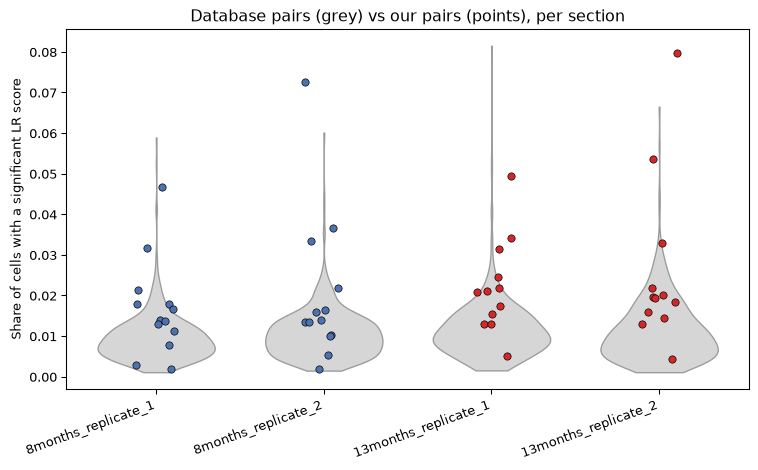

,,count,25%,50%,75%
section,age,,,,
13months_replicate_1,13months,406.0,0.007434,0.010510,0.014612
13months_replicate_2,13months,374.0,0.005650,0.009778,0.015211
8months_replicate_1,8months,414.0,0.005676,0.008649,0.011892
8months_replicate_2,8months,405.0,0.006135,0.009816,0.013497


In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
db_vals = [summary_all.loc[(summary_all["section"] == s) & ~summary_all["is_ours"], "frac_sig"].to_numpy() for s in sections]
parts = ax.violinplot(db_vals, positions=range(len(sections)), showextrema=False, widths=0.7)
for b in parts["bodies"]:
    b.set_facecolor("#cccccc"); b.set_edgecolor("#888888"); b.set_alpha(0.8)
age_colors = {young_age: "#4c72b0", old_age: "#d62728"}
rng = np.random.default_rng(0)
for i, s in enumerate(sections):
    o = summary_all[(summary_all["section"] == s) & summary_all["is_ours"]]
    ax.scatter(i + rng.uniform(-0.12, 0.12, len(o)), o["frac_sig"], color=age_colors[section_age[s]],
               s=30, edgecolors="black", linewidths=0.5, zorder=3)
ax.set_xticks(range(len(sections))); ax.set_xticklabels(sections, rotation=20, ha="right")
ax.set_ylabel("Share of cells with a significant LR score")
ax.set_title("Database pairs (grey) vs our pairs (points), per section")
plt.tight_layout()
plt.savefig(f"{out_dir}/stlearn_frac_sig_by_section.png", dpi=200, bbox_inches="tight")
plt.show()

summary_all[~summary_all["is_ours"]].groupby(["section", "age"])["frac_sig"].describe()[["count", "25%", "50%", "75%"]]

## Are our pairs above detection-matched database pairs?

Per section: one-sided empirical p vs the `K_MATCHED` database pairs with the closest ligand and receptor detection. Combined across the 4 sections (and per age) with Stouffer, then BH across our pairs; `beyond_db` = `p_adj < 0.05`.

In [7]:
p_wide = matched_all.pivot_table(index="lr", columns="section", values="p_matched")
p_wide = p_wide[[s for s in sections if s in p_wide.columns]].add_prefix("p_")

vs_db = (
    matched_all.groupby("lr")
    .agg(mean_frac_sig=("frac_sig", "mean"), mean_matched_median=("matched_median", "mean"),
         n_sections=("section", "nunique"))
    .join(p_wide)
)
vs_db["p_combined"] = matched_all.groupby("lr")["p_matched"].apply(stouffer)
for age, tag in [(young_age, "young"), (old_age, "old")]:
    vs_db[f"p_combined_{tag}"] = matched_all[matched_all["age"] == age].groupby("lr")["p_matched"].apply(stouffer)
vs_db["p_adj"] = bh_adjust(vs_db["p_combined"])
vs_db["beyond_db"] = vs_db["p_adj"] < 0.05
vs_db = vs_db.sort_values("p_combined")

print(f"{vs_db['beyond_db'].sum()}/{len(vs_db)} of our pairs are significant in more cells than "
      f"detection-matched database pairs (Stouffer across sections, BH p_adj < 0.05)")
vs_db

2/13 of our pairs are significant in more cells than detection-matched database pairs (Stouffer across sections, BH p_adj < 0.05)


,mean_frac_sig,mean_matched_median,n_sections,p_8months_replicate_1,p_8months_replicate_2,p_13months_replicate_1,p_13months_replicate_2,p_combined,p_combined_young,p_combined_old,p_adj,beyond_db
lr,,,,,,,,,,,,
App_Aplp1,0.062154,0.018376,4,0.058824,0.019608,0.078431,0.019608,0.000191,0.005167,0.006965,0.002484,True
Cxcl12_Itgb1,0.033773,0.016809,4,0.039216,0.058824,0.058824,0.078431,0.000809,0.009366,0.017538,0.005261,True
Calm1_Ptpra,0.034104,0.018632,4,0.392157,0.098039,0.137255,0.039216,0.013568,0.133998,0.021843,0.058795,False
Bsg_Slc16a7,0.022437,0.016973,4,0.117647,0.235294,0.117647,0.490196,0.059394,0.088603,0.195834,0.193030,False
Adam10_Notch2,0.016201,0.013119,4,0.137255,0.235294,0.137255,0.509804,0.074763,0.099768,0.225034,0.194384,False
Ptn_Ptprs,0.016634,0.014092,4,0.647059,0.215686,0.176471,0.274510,0.166325,0.386089,0.139949,0.360370,False
Apoe_Sorl1,0.016062,0.013795,4,0.196078,0.882353,0.117647,0.450980,0.312262,0.592560,0.177140,0.509014,False
Pdgfa_Pdgfra,0.015890,0.014386,4,0.313725,0.352941,0.666667,0.294118,0.313239,0.270922,0.468813,0.509014,False
Cd14_Itgb1,0.014428,0.013712,4,0.431373,0.588235,0.411765,0.470588,0.450920,0.514138,0.416885,0.616870,False


## Age shift

For our pairs, on raw `frac_sig` and on `frac_sig_rel` (relative to the section's database pairs). A shift counts only if both sections of one age lie above (or below) both sections of the other; otherwise `intermixed`.

In [8]:
ours_all = summary_all[summary_all["is_ours"]].copy()

def classify_shift(df, col):
    rows = []
    for lr, g in df.groupby("lr"):
        y = g.loc[g["age"] == young_age, col].to_numpy()
        o = g.loc[g["age"] == old_age, col].to_numpy()
        if len(y) == 0 or len(o) == 0:
            direction = "missing_section"
        elif o.min() > y.max():
            direction = "increase_with_age"
        elif o.max() < y.min():
            direction = "decrease_with_age"
        else:
            direction = "intermixed"
        rows.append({"lr": lr, f"mean_young_{col}": np.mean(y) if len(y) else np.nan,
                     f"mean_old_{col}": np.mean(o) if len(o) else np.nan,
                     f"shift_{col}": direction})
    return pd.DataFrame(rows).set_index("lr")

age_shift = classify_shift(ours_all, "frac_sig").join(classify_shift(ours_all, "frac_sig_rel"))
age_shift["delta_frac_sig"] = age_shift["mean_old_frac_sig"] - age_shift["mean_young_frac_sig"]
age_shift = age_shift.join(vs_db[["p_adj", "beyond_db"]])
print(age_shift["shift_frac_sig"].value_counts().to_string())
age_shift.sort_values("delta_frac_sig")

shift_frac_sig
intermixed           7
increase_with_age    5
missing_section      1


,mean_young_frac_sig,mean_old_frac_sig,shift_frac_sig,mean_young_frac_sig_rel,mean_old_frac_sig_rel,shift_frac_sig_rel,delta_frac_sig,p_adj,beyond_db
lr,,,,,,,,,
Cxcl12_Itgb1,0.034093,0.033453,intermixed,3.690625,3.299729,decrease_with_age,-0.000640,0.005261,True
Igfbpl1_Dcc,0.004186,0.004736,intermixed,0.446875,0.466125,intermixed,0.000551,0.997836,False
Pdgfa_Pdgfra,0.015248,0.016532,intermixed,1.650000,1.644173,intermixed,0.001285,0.509014,False
Adam10_Notch2,0.015372,0.017029,intermixed,1.681250,1.666667,intermixed,0.001657,0.194384,False
Bsg_Slc16a7,0.021596,0.023278,increase_with_age,2.346875,2.292954,intermixed,0.001682,0.193030,False
Cd14_Itgb1,0.013235,0.015622,increase_with_age,1.437500,1.542818,intermixed,0.002387,0.616870,False
Apoe_Sorl1,0.013950,0.018174,intermixed,1.543750,1.781030,intermixed,0.004224,0.509014,False
Fgfr3_Epha4,0.013640,0.018385,increase_with_age,1.484375,1.818157,increase_with_age,0.004745,0.616870,False
App_Aplp1,0.059697,0.064611,intermixed,6.403125,6.431436,intermixed,0.004914,0.002484,True


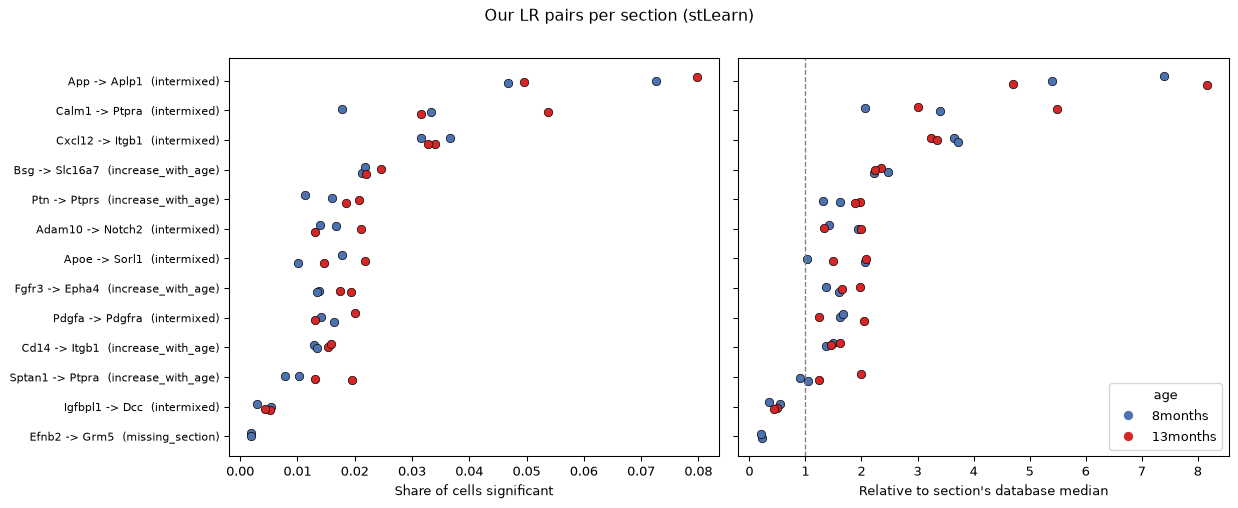

In [9]:
pair_order = ours_all.groupby("lr")["frac_sig"].mean().sort_values(ascending=False).index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(13, max(4, 0.4 * len(pair_order))), sharey=True)
for ax, col, xlab in [(axes[0], "frac_sig", "Share of cells significant"),
                      (axes[1], "frac_sig_rel", "Relative to section's database median")]:
    for _, r in ours_all.iterrows():
        y = pair_order.index(r["lr"]) + rng.uniform(-0.15, 0.15)
        ax.scatter(r[col], y, color=age_colors[r["age"]], s=40, edgecolors="black", linewidths=0.5)
    ax.set_xlabel(xlab)
    if col == "frac_sig_rel":
        ax.axvline(1, color="grey", linestyle="--", linewidth=1)
axes[0].set_yticks(range(len(pair_order)))
axes[0].set_yticklabels([f"{lr_label(lr)}  ({age_shift.loc[lr, 'shift_frac_sig']})" for lr in pair_order], fontsize=8)
axes[0].invert_yaxis()
handles = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=c, markersize=8, label=a)
           for a, c in age_colors.items()]
axes[1].legend(handles=handles, title="age", loc="lower right")
plt.suptitle("Our LR pairs per section (stLearn)", y=1.01)
plt.tight_layout()
plt.show()

## Agreement with bivariate Moran's I (`10`)

Age direction from stLearn (`frac_sig`) next to the Moran's I direction from `10`, if `10` has been run.

In [10]:
if os.path.exists(morans_shift_path):
    morans = pd.read_csv(morans_shift_path)
    morans["lr"] = morans["pair_label"].str.replace(" -> ", "_", regex=False)
    method_cmp = age_shift[["shift_frac_sig", "shift_frac_sig_rel", "delta_frac_sig"]].join(
        morans.set_index("lr")[["shift_direction", "delta"]].rename(
            columns={"shift_direction": "shift_morans", "delta": "delta_morans"}), how="left")
    both = method_cmp.dropna(subset=["shift_morans"])
    clear = both[(both["shift_frac_sig"] != "intermixed") & (both["shift_morans"] != "intermixed")]
    print(f"Pairs with a clear shift in both methods: {len(clear)}; same direction: "
          f"{(clear['shift_frac_sig'] == clear['shift_morans']).sum()}")
    display(method_cmp)
else:
    method_cmp = None
    print(f"{morans_shift_path} not found -- run 10 first for the comparison.")

Pairs with a clear shift in both methods: 2; same direction: 2


,shift_frac_sig,shift_frac_sig_rel,delta_frac_sig,shift_morans,delta_morans
lr,,,,,
Adam10_Notch2,intermixed,intermixed,0.001657,increase_with_age,0.004969
Apoe_Sorl1,intermixed,intermixed,0.004224,increase_with_age,0.008041
App_Aplp1,intermixed,intermixed,0.004914,decrease_with_age,-0.030249
Bsg_Slc16a7,increase_with_age,intermixed,0.001682,intermixed,0.001341
Calm1_Ptpra,intermixed,intermixed,0.016995,decrease_with_age,-0.002363
Cd14_Itgb1,increase_with_age,intermixed,0.002387,increase_with_age,0.004508
Cxcl12_Itgb1,intermixed,decrease_with_age,-0.000640,intermixed,0.001587
Efnb2_Grm5,missing_section,missing_section,NaN,intermixed,-0.000780
Fgfr3_Epha4,increase_with_age,increase_with_age,0.004745,intermixed,0.002707


## Cell-type interactions by age

Number of **cell–neighbour pairs** per age (mean of the 2 sections) for each of our pairs, and the old − young difference. A pair = a significant cell (row type) and one of its neighbours within `RADIUS` (column type), with the ligand in one and the receptor in the other (either direction); the neighbour does not need to be significant, so counts can be much larger than the number of significant cells (shown in the panel titles). Counts scale with how many cells are significant, so read them together with `frac_sig`.

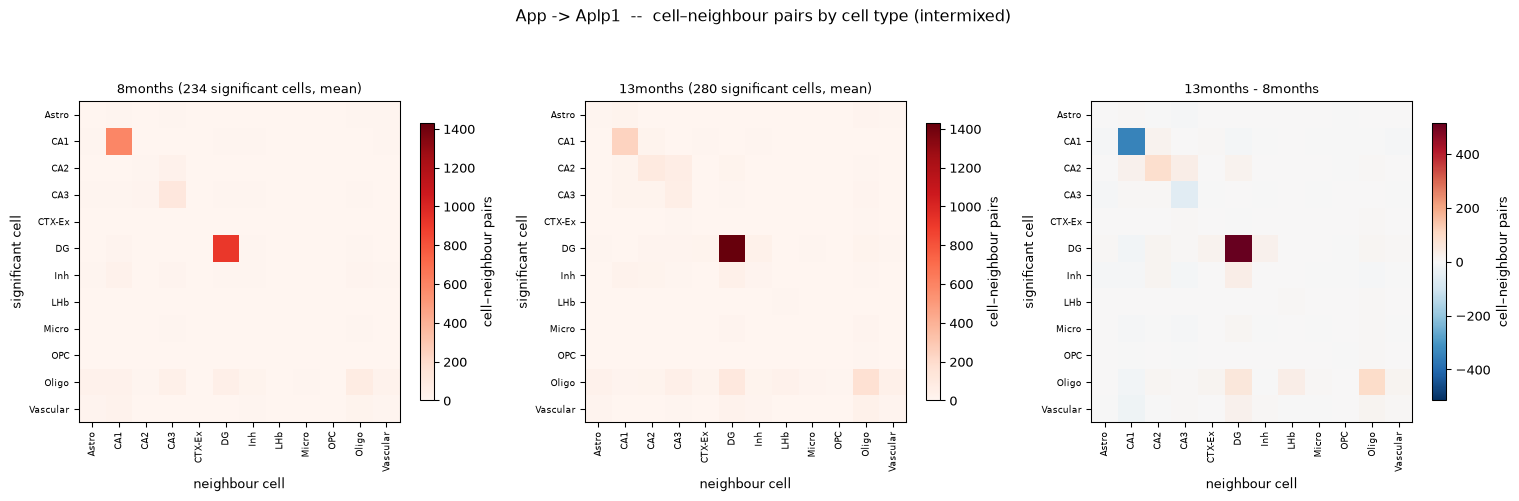

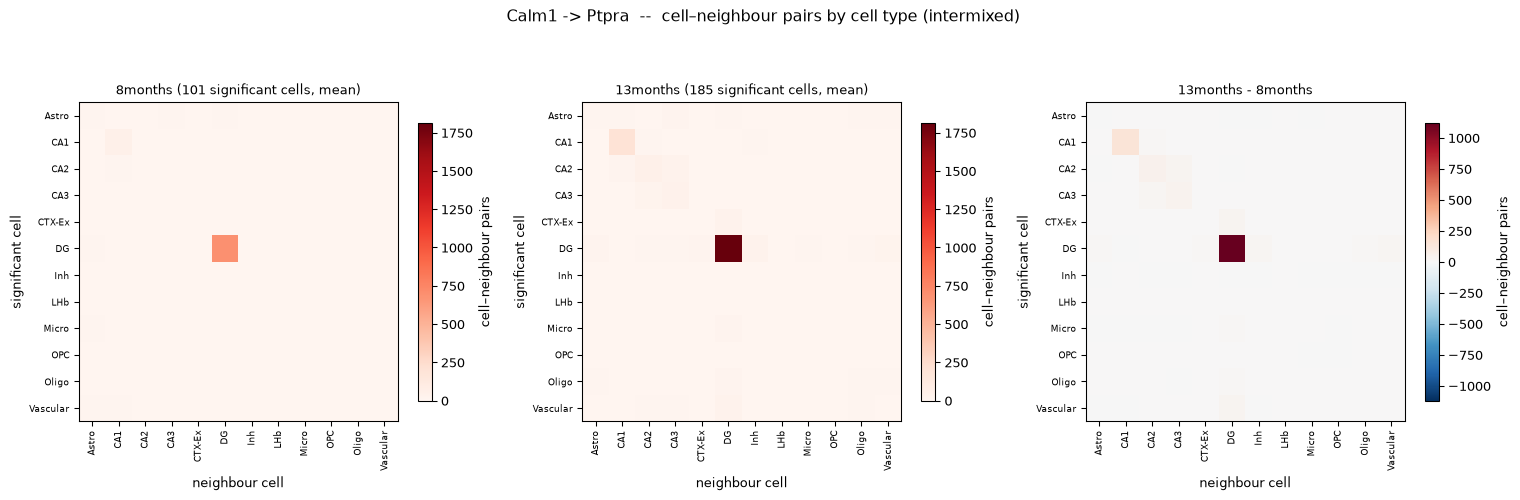

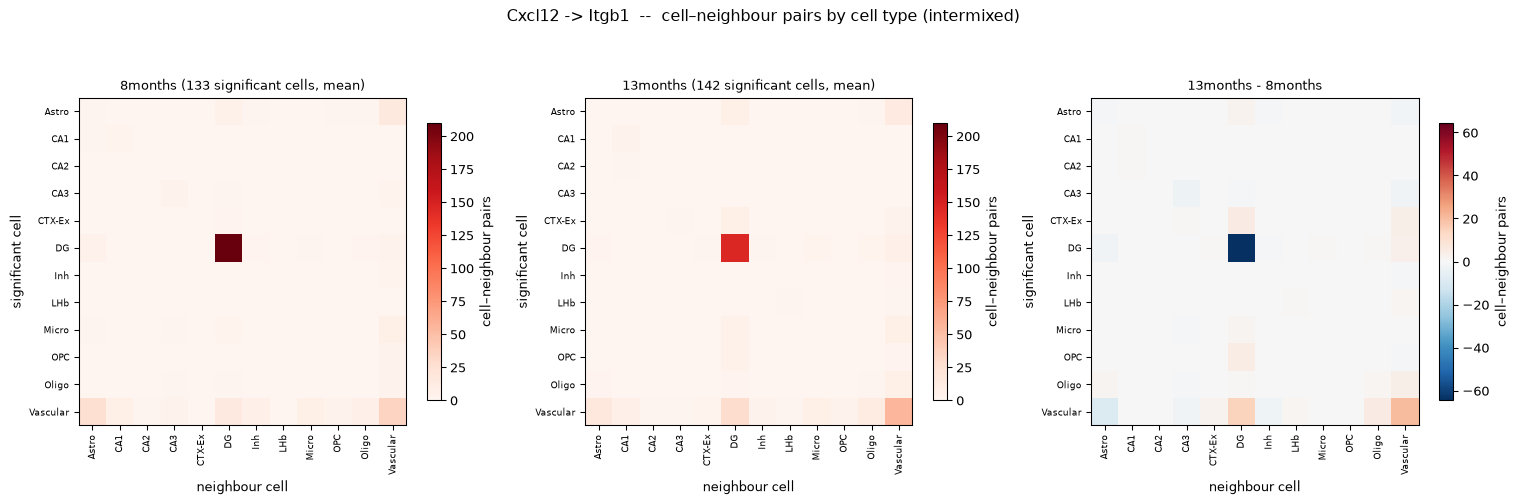

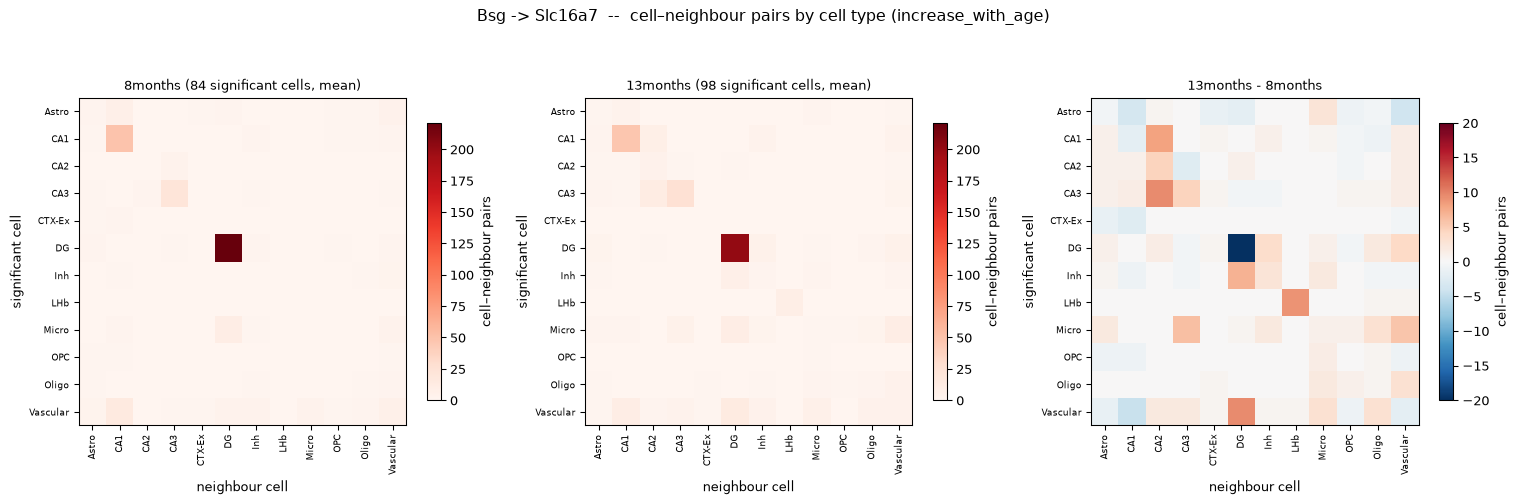

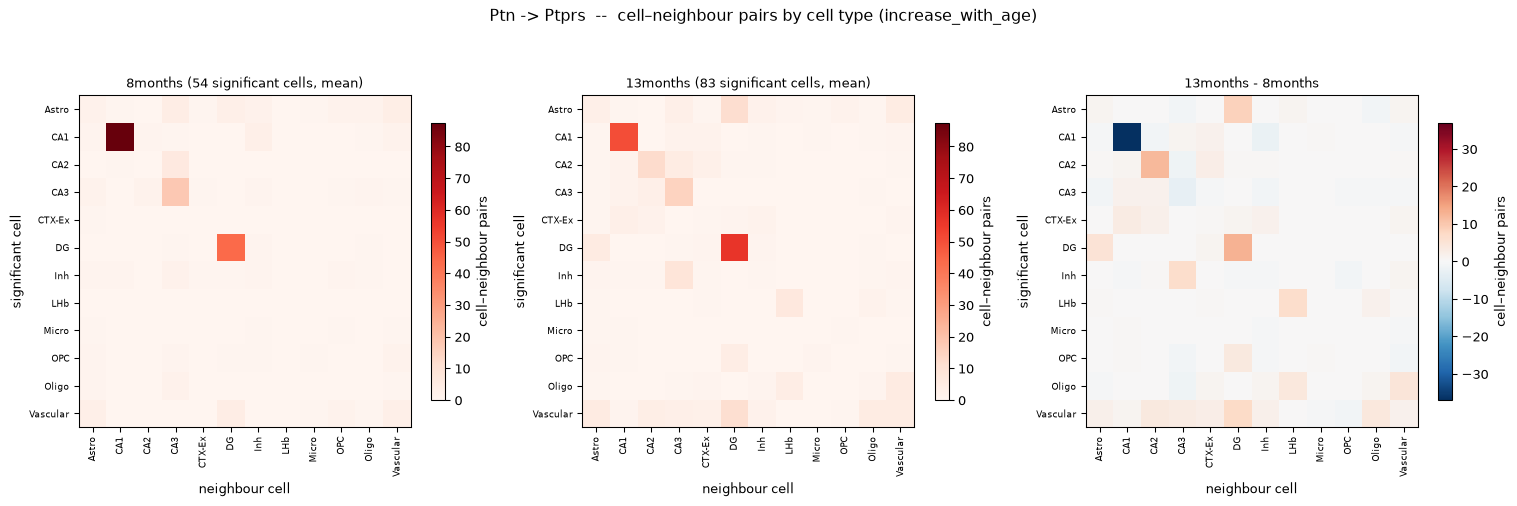

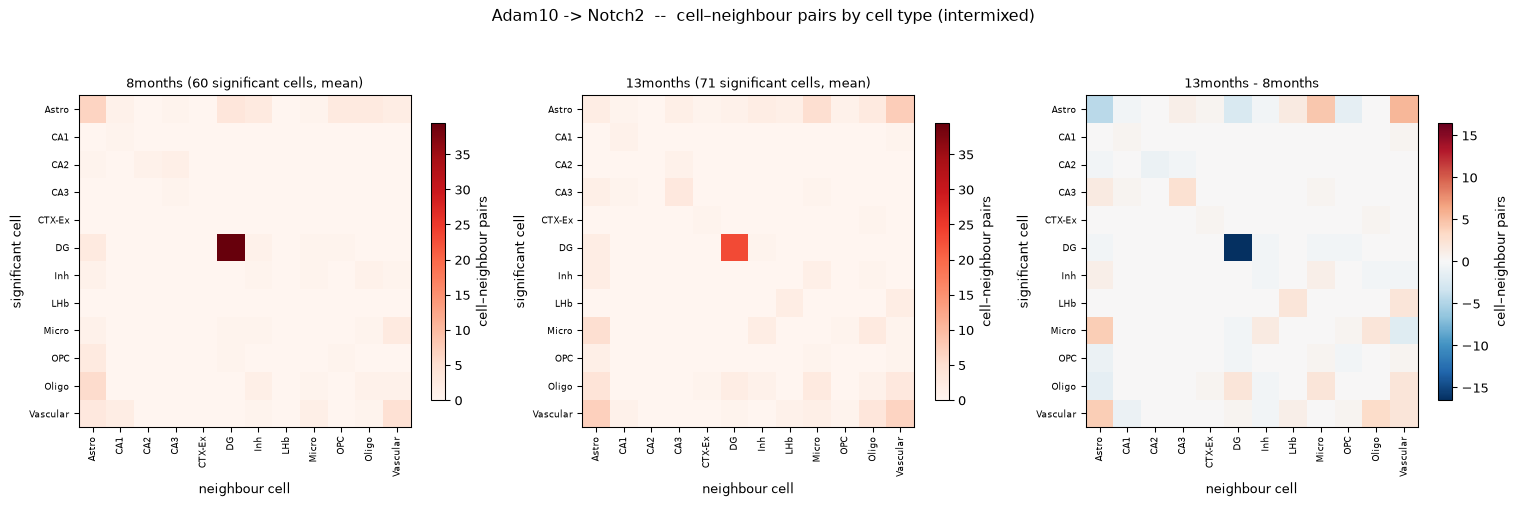

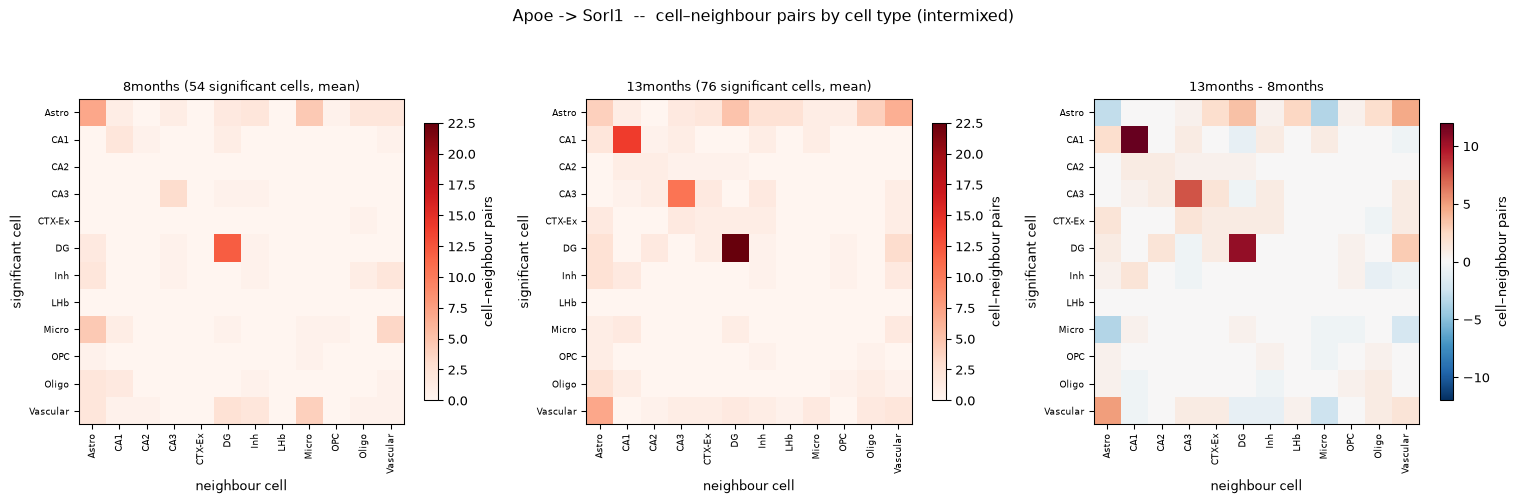

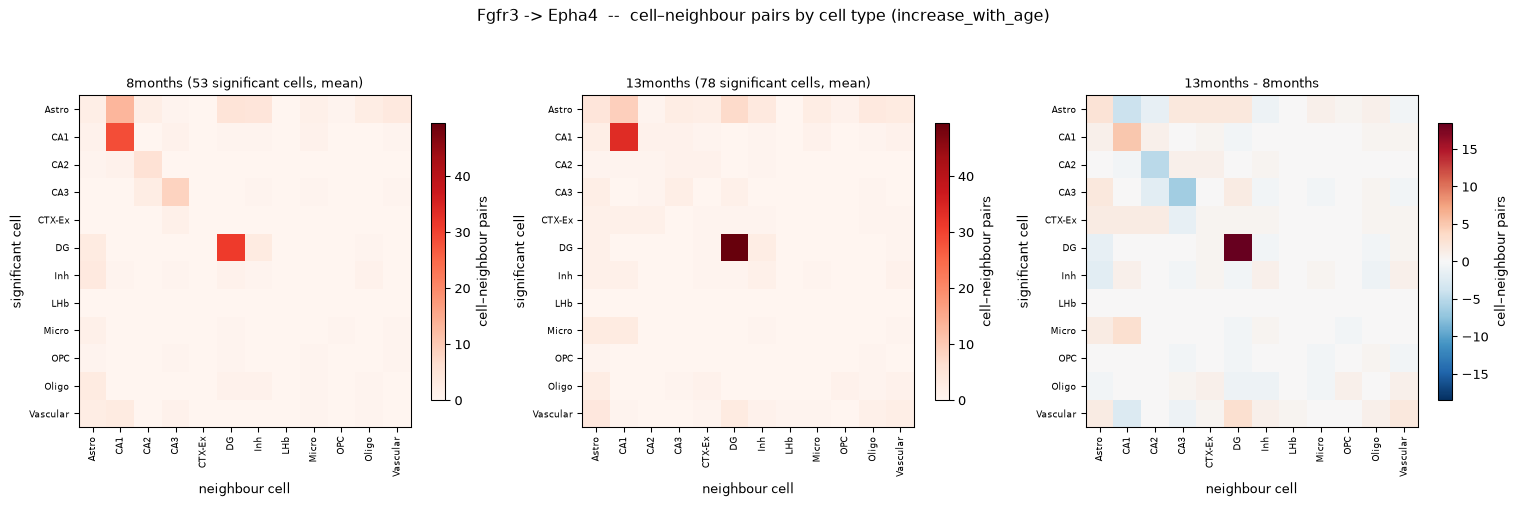

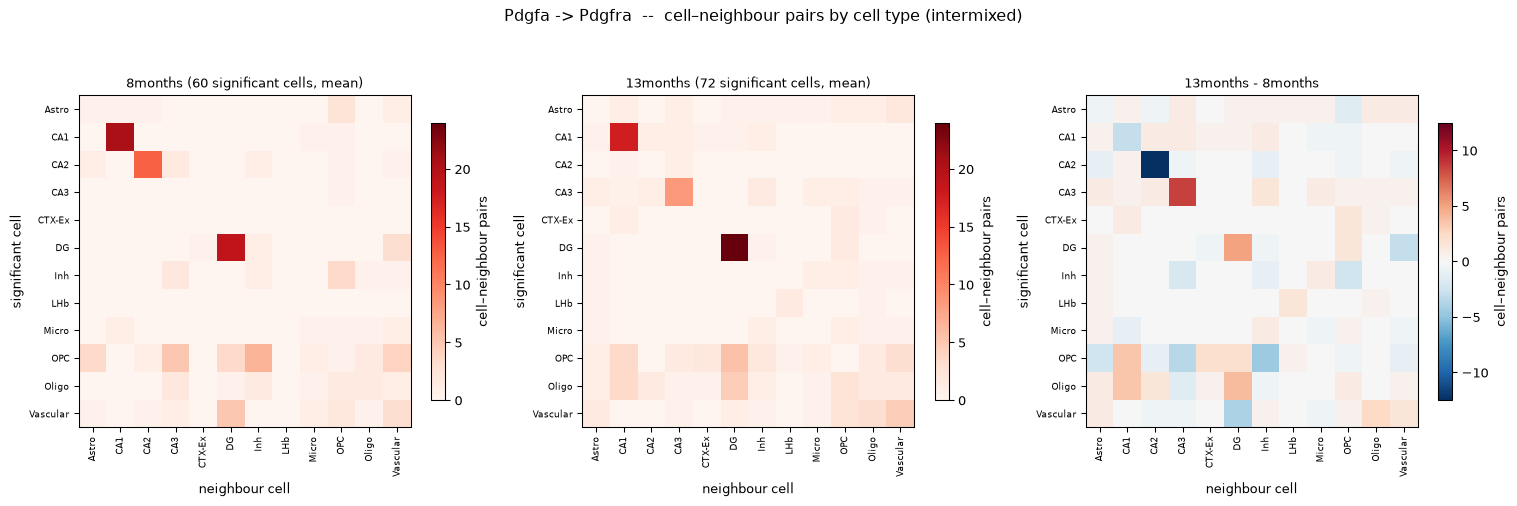

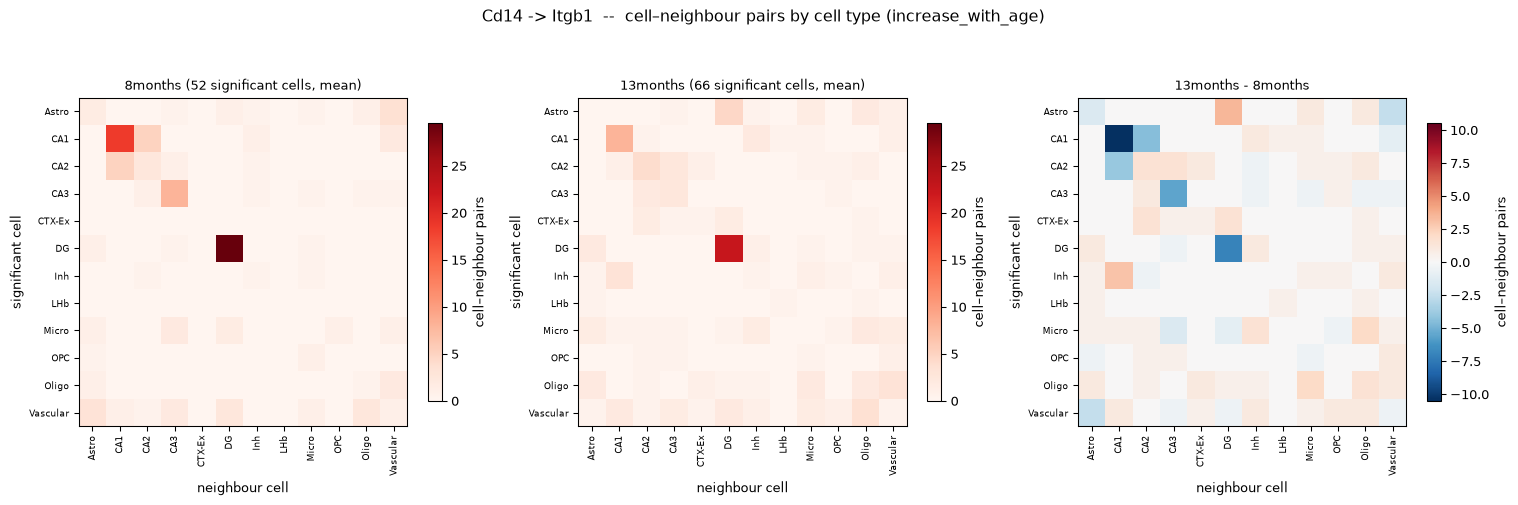

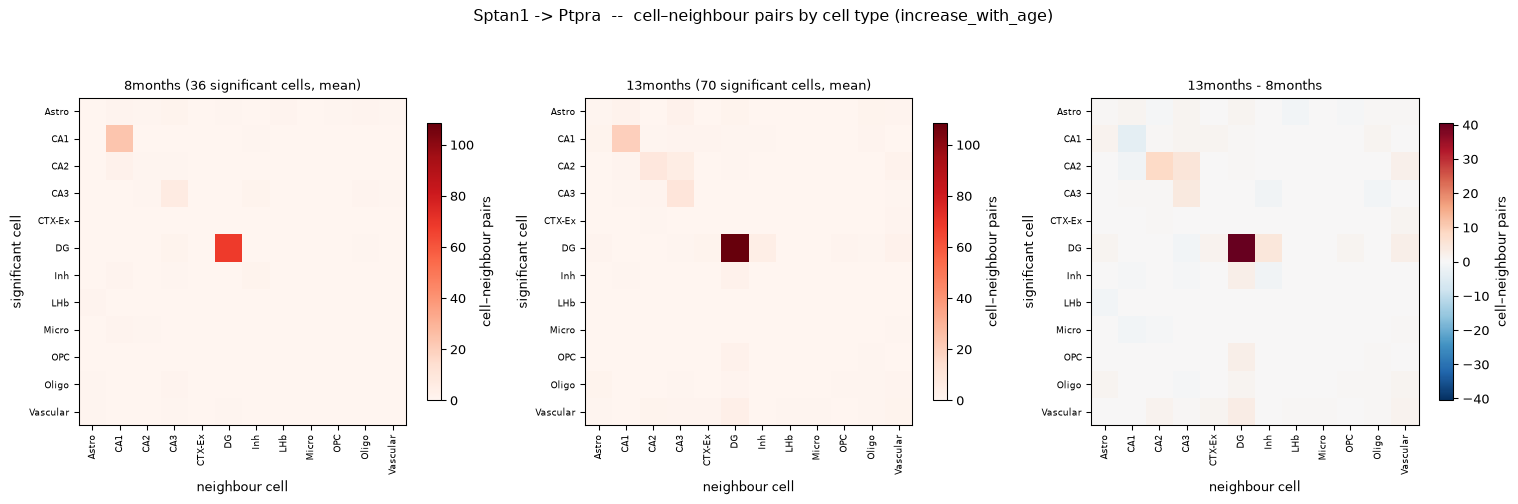

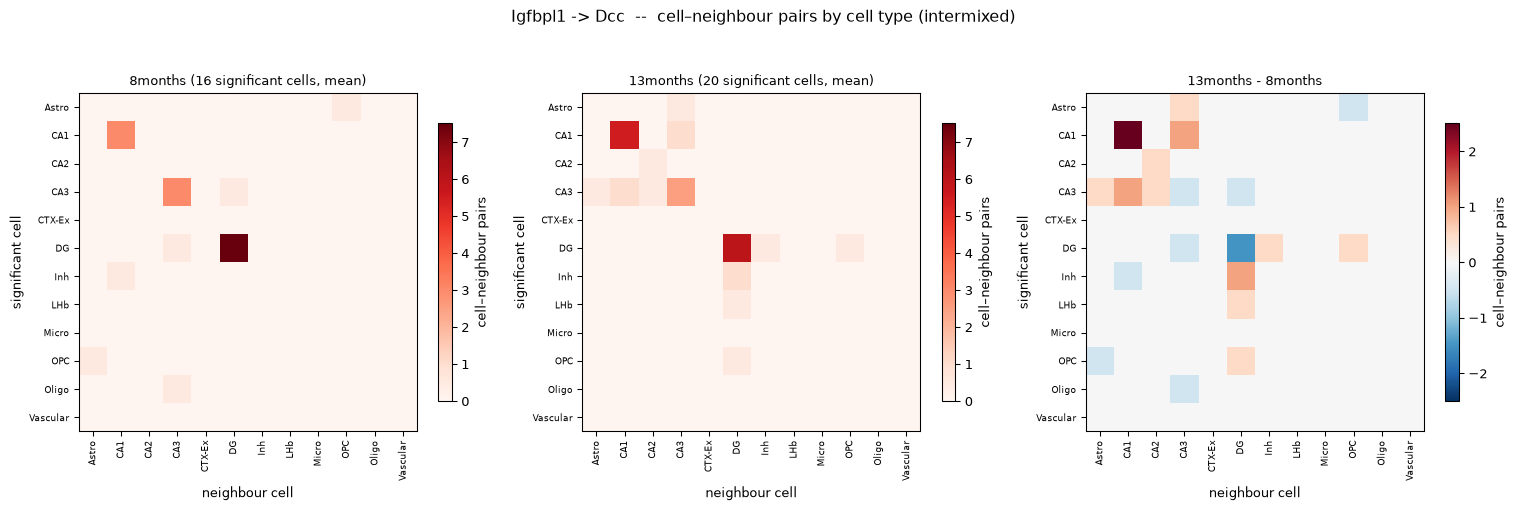

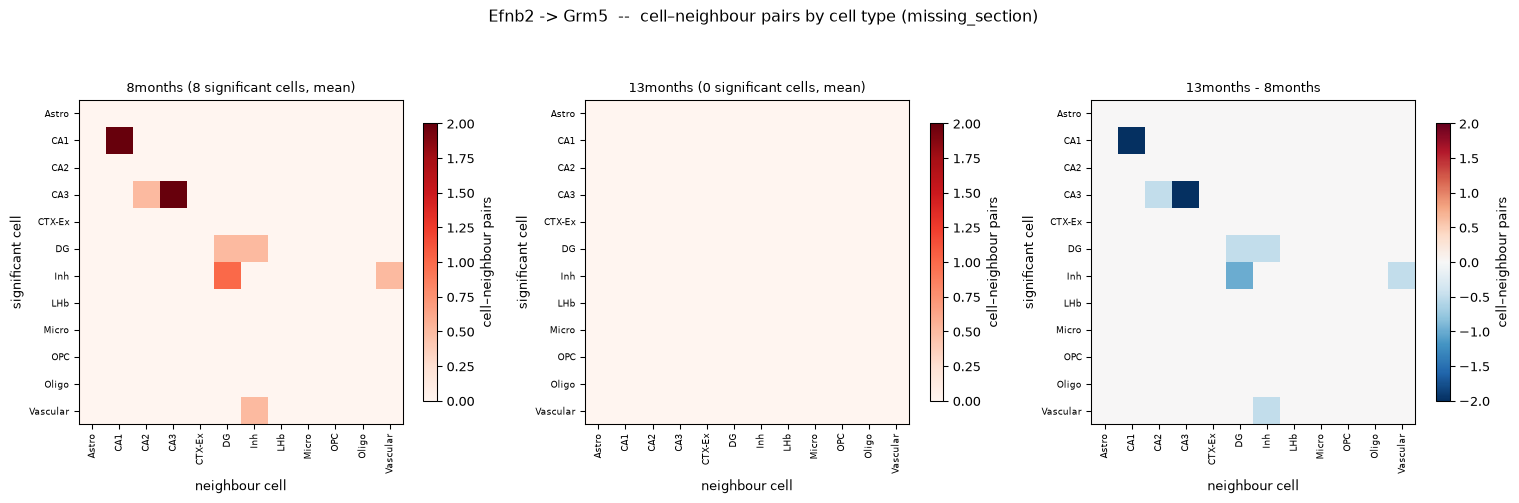

In [11]:
if len(cci_all):
    cci_age = (cci_all.groupby(["lr", "age", "celltype_sig_cell", "celltype_neighbour"])["n_interactions"]
               .mean().reset_index())
    for lr in [l for l in pair_order if l in set(cci_age["lr"])]:
        sub = cci_age[cci_age["lr"] == lr]
        mats = {age: sub[sub["age"] == age].pivot(index="celltype_sig_cell", columns="celltype_neighbour",
                                                  values="n_interactions")
                for age in (young_age, old_age)}
        types = sorted(set().union(*[set(m.index) | set(m.columns) for m in mats.values()]))
        mats = {k: v.reindex(index=types, columns=types).fillna(0) for k, v in mats.items()}
        diff = mats[old_age] - mats[young_age]
        vmax = max(m.to_numpy().max() for m in mats.values()) or 1
        dmax = np.abs(diff.to_numpy()).max() or 1

        fig, axes = plt.subplots(1, 3, figsize=(16, 5))
        n_sig = ours_all[ours_all["lr"] == lr].groupby("age")["n_spots_sig"].mean()
        for ax, (title, m, cmap, vmin, vmx) in zip(axes, [
                (f"{young_age} ({n_sig.get(young_age, 0):.0f} significant cells, mean)", mats[young_age], "Reds", 0, vmax),
                (f"{old_age} ({n_sig.get(old_age, 0):.0f} significant cells, mean)", mats[old_age], "Reds", 0, vmax),
                (f"{old_age} - {young_age}", diff, "RdBu_r", -dmax, dmax)]):
            im = ax.imshow(m.to_numpy(), cmap=cmap, vmin=vmin, vmax=vmx)
            ax.set_xticks(range(len(types))); ax.set_xticklabels(types, rotation=90, fontsize=7)
            ax.set_yticks(range(len(types))); ax.set_yticklabels(types, fontsize=7)
            ax.set_xlabel("neighbour cell"); ax.set_ylabel("significant cell")
            ax.set_title(title, fontsize=10)
            plt.colorbar(im, ax=ax, shrink=0.7, label="cell–neighbour pairs")
        plt.suptitle(f"{lr_label(lr)}  --  cell–neighbour pairs by cell type ({age_shift.loc[lr, 'shift_frac_sig']})", y=1.02)
        plt.tight_layout()
        plt.show()
else:
    print("No cell-type CCI results.")

## Save results

In [12]:
summary_all.to_csv(f"{out_dir}/stlearn_lr_summary_by_section.csv", index=False)
matched_all.to_csv(f"{out_dir}/stlearn_our_pairs_vs_matched_db_by_section.csv", index=False)
vs_db.reset_index().to_csv(f"{out_dir}/stlearn_our_pairs_vs_db_summary.csv", index=False)
age_shift.reset_index().to_csv(f"{out_dir}/stlearn_age_shift.csv", index=False)
if method_cmp is not None:
    method_cmp.reset_index().to_csv(f"{out_dir}/stlearn_vs_morans_age_shift.csv", index=False)
if len(cci_all):
    cci_all.to_csv(f"{out_dir}/stlearn_celltype_cci_by_section.csv", index=False)
print("Saved to", out_dir)

Saved to output/10b_STARmapPLUS_stlearn_Age_comparison


## Notes

- stLearn's per-cell p-values already compare each pair with random gene pairs of similar expression; `beyond_db` asks a second question: does the pair reach significance in more cells than known LR pairs with similar detection?
- With n = 2 sections per age, the age shift is descriptive.
- `frac_sig_rel` removes a section-wide offset (all pairs higher in one section); prefer it over raw `frac_sig` when they disagree.